# Etapa 1 — Diagnóstico e preparação: risco de incêndio por município e dia

**O problema.** Brigadas e defesa civil precisam decidir, todo dia, onde deixar equipes de prontidão. O
modelo deste projeto vai prever o **nível de risco de incêndio (Baixo, Médio ou Alto) para cada município
e dia**, usando só o que se sabe até a véspera.

**As bases** (Base dos Dados, fornecidas pela TripleTen): focos de queimada do INPE, uso do solo do
MapBiomas e medições meteorológicas do INMET (BDMEP), por estação.

**O ponto de partida: o dado que falta.** Na Segunda Guerra, o estatístico Abraham Wald analisou os
aviões que voltavam de combate cheios de buracos nas asas. A conclusão certa não era blindar as asas, e
sim onde *não* havia buracos: os aviões atingidos ali não voltaram para entrar na estatística. A base de
queimadas tem o mesmo **viés de sobrevivência**: ela só registra onde o satélite viu fogo. Os municípios
e dias sem fogo, que são exatamente os de risco baixo, não aparecem. Este notebook mostra esse viés com
números e monta uma base que inclui esses dias.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, 'src')
import consolidar_base as cb

con = cb.conectar()
q = lambda sql: con.sql(sql).df()

AZUL, CINZA, LARANJA, VERMELHO = '#2f6fdb', '#9aa5b1', '#e8a33d', '#c0392b'
CORES_RISCO = {'Baixo': CINZA, 'Médio': LARANJA, 'Alto': VERMELHO}

## 1. As bases brutas

In [2]:
resumo = q('''
    SELECT 'queimadas' AS base, count(*) AS linhas, min(CAST(data_hora AS DATE)) AS inicio, max(CAST(data_hora AS DATE)) AS fim FROM queimadas
    UNION ALL SELECT 'bdmep', count(*), min(data), max(data) FROM bdmep
    UNION ALL SELECT 'mapbiomas', count(*), make_date(min(ano), 1, 1), make_date(max(ano), 12, 31) FROM mapbiomas
    UNION ALL SELECT 'estacoes (cadastro)', count(*), NULL, NULL FROM estacoes
''')
resumo

,base,linhas,inicio,fim
0,queimadas,8226944,2024-01-01,2025-02-12
1,bdmep,4891176,2025-01-01,2025-06-30
2,mapbiomas,2286656,1985-01-01,2021-12-31
3,estacoes (cadastro),612,NaT,NaT


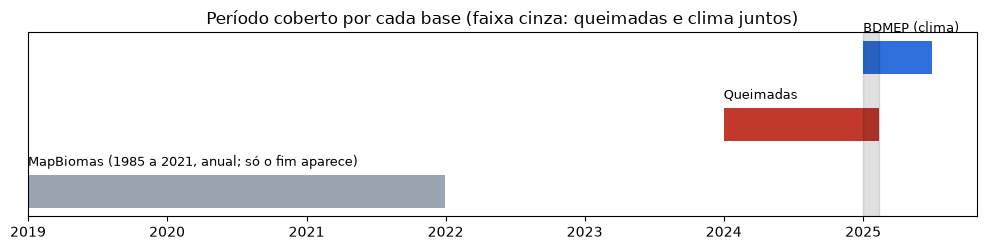

Dias em que queimadas e BDMEP coexistem: 43


In [3]:
fig, eixo = plt.subplots(figsize=(10, 2.6))
periodos = [('MapBiomas (1985 a 2021, anual; só o fim aparece)', '2019-01-01', '2021-12-31', CINZA),
            ('Queimadas', '2024-01-01', '2025-02-12', VERMELHO),
            ('BDMEP (clima)', '2025-01-01', '2025-06-30', AZUL)]
for i, (nome, ini, fim, cor) in enumerate(periodos):
    ini, fim = pd.Timestamp(ini), pd.Timestamp(fim)
    eixo.barh(i, (fim - ini).days, left=ini, color=cor, height=0.5)
    eixo.text(ini, i + 0.38, nome, fontsize=9)
eixo.axvspan(pd.Timestamp('2025-01-01'), pd.Timestamp('2025-02-12'), color='black', alpha=0.12)
eixo.set_yticks([])
eixo.set_title('Período coberto por cada base (faixa cinza: queimadas e clima juntos)')
plt.tight_layout()
plt.show()

comum = q('''SELECT count(DISTINCT data) AS dias FROM bdmep
             WHERE data <= (SELECT max(CAST(data_hora AS DATE)) FROM queimadas)''')['dias'].iloc[0]
print(f'Dias em que queimadas e BDMEP coexistem: {comum}')

**As bases quase não se encontram no tempo.** As queimadas vão de janeiro de 2024 a 12 de fevereiro de
2025; o BDMEP só cobre janeiro a junho de 2025. As duas coexistem em só 43 dias, em plena época de
chuva. O MapBiomas termina em 2021. Consequências:

- **O clima do BDMEP não serve como feature** para 2024 inteiro. Ele entra na seção 7, para testar uma
  hipótese no período em que as bases coexistem.
- **O uso do solo vem de 2021**, o ano mais recente disponível. Para uma característica que muda devagar,
  como a proporção de pastagem de um município, é uma aproximação razoável; a limitação fica registrada.

## 2. Qualidade dos dados brutos

In [4]:
qualidade = q('''
    SELECT count(*) AS focos,
        count(*) - count(DISTINCT (data_hora, latitude, longitude, satelite)) AS duplicados,
        count(*) FILTER (WHERE risco_fogo IS NULL) AS risco_nulo,
        count(*) FILTER (WHERE risco_fogo < 0) AS risco_menos_999,
        count(*) FILTER (WHERE dias_sem_chuva < 0) AS dias_sem_chuva_menos_999,
        count(*) FILTER (WHERE precipitacao IS NULL) AS precipitacao_nula
    FROM queimadas
''')
qualidade.T.rename(columns={0: 'contagem'})

,contagem
focos,8226944
duplicados,4
risco_nulo,112670
risco_menos_999,89779
dias_sem_chuva_menos_999,64106
precipitacao_nula,112670


In [5]:
bdmep_qualidade = q('''
    SELECT count(*) AS linhas,
        (SELECT count(*) FROM (SELECT DISTINCT * FROM bdmep)) AS linhas_distintas,
        count(DISTINCT (id_estacao, data, hora)) AS estacao_dia_hora,
        count(*) FILTER (WHERE umidade_rel_min IS NULL) AS umidade_min_vazia,
        min(umidade_rel_min) AS umidade_min_menor, max(umidade_rel_min) AS umidade_min_maior
    FROM bdmep
''')
bdmep_qualidade.T.rename(columns={0: 'BDMEP'})

,BDMEP
linhas,4891176.0
linhas_distintas,2463184.0
estacao_dia_hora,2452104.0
umidade_min_vazia,1623709.0
umidade_min_menor,7.0
umidade_min_maior,100.0


In [6]:
fora_do_mapbiomas = q('''
    SELECT count(DISTINCT id_municipio) AS municipios, count(*) AS focos FROM queimadas
    WHERE id_municipio NOT IN (SELECT id_municipio FROM mapbiomas)
''')
print(fora_do_mapbiomas)
print()
print('Códigos de classe no MapBiomas:', q('SELECT DISTINCT id_classe FROM mapbiomas ORDER BY 1')['id_classe'].tolist())

   municipios  focos
0           3   1130

Códigos de classe no MapBiomas: [0, 3, 4, 5, 9, 11, 12, 13, 15, 20, 21, 23, 24, 25, 29, 30, 31, 32, 33, 39, 40, 41, 46, 47, 48, 49, 50, 62]


- **Duplicados:** 4 focos aparecem repetidos (mesma hora, posição e satélite). A contagem da seção 4
  ignora as repetições.
- **Valores-código:** 89 779 focos têm `risco_fogo = -999` e 112 670 estão sem risco; 64 106 têm
  `dias_sem_chuva = -999`. São códigos de "sem informação". Como essas colunas não entram no modelo
  (seção 3), elas só pesam na análise do `risco_fogo`, onde são descartadas.
- **BDMEP em dobro:** o arquivo tem 4 891 176 linhas, mas só 2 452 104 combinações de estação, dia e hora.
  Quase toda medição aparece duas vezes, idêntica. O teste da seção 7.2 usa só as linhas distintas. Além
  disso, 1 623 709 medições de umidade mínima estão vazias e ficam fora; as preenchidas vão de 7% a
  100%, sem valores impossíveis.
- **Focos sem município no MapBiomas:** 3 municípios (1 130 focos) não existem na base do MapBiomas,
  provavelmente municípios criados depois de 2021. Ficam fora da grade.
- **O dicionário do MapBiomas não bate com os dados.** O dicionário fornecido fala em 7 classes, mas o
  arquivo tem 28 códigos, que são os da **legenda oficial da Coleção 8 do MapBiomas** (3 = formação
  florestal, 15 = pastagem, 39 = soja, 24 = área urbanizada etc.). A consolidação agrupa esses códigos
  em 7 grupos de uso do solo; o mapeamento está em `src/consolidar_base.py` e no `dicionario_dados.txt`.

## 3. O viés de sobrevivência, com números

O `risco_fogo` é o risco calculado pelo INPE para o dia. Mas ele só existe nas linhas da base, ou seja,
**só nos lugares onde já havia fogo**:

                             focos      %
faixa_inpe                               
1. mínimo (< 0,15)          473101   5.90
2. baixo (0,15 a 0,40)      377036   4.70
3. médio (0,40 a 0,70)      635404   7.92
4. alto (0,70 a 0,95)      1161476  14.47
5. crítico (0,95 ou mais)  5377478  67.01


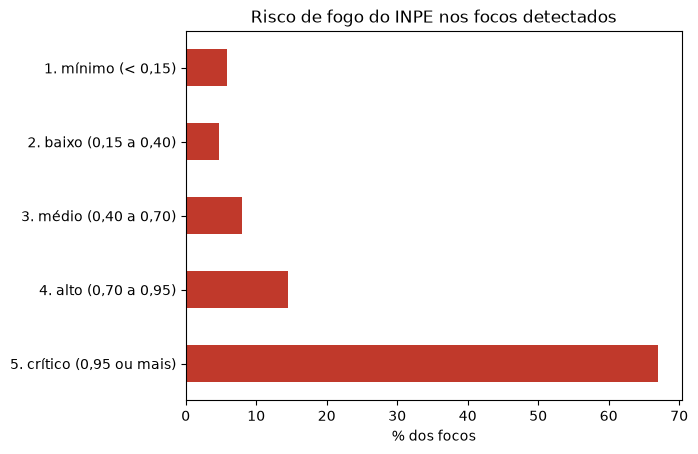

In [7]:
risco = q('''
    SELECT CASE WHEN risco_fogo < 0.15 THEN '1. mínimo (< 0,15)'
                WHEN risco_fogo < 0.40 THEN '2. baixo (0,15 a 0,40)'
                WHEN risco_fogo < 0.70 THEN '3. médio (0,40 a 0,70)'
                WHEN risco_fogo < 0.95 THEN '4. alto (0,70 a 0,95)'
                ELSE '5. crítico (0,95 ou mais)' END AS faixa_inpe,
           count(*) AS focos
    FROM queimadas WHERE risco_fogo >= 0
    GROUP BY 1 ORDER BY 1
''').set_index('faixa_inpe')
risco['%'] = (risco['focos'] / risco['focos'].sum() * 100).round(2)
print(risco)

risco['%'].plot(kind='barh', color=VERMELHO)
plt.gca().invert_yaxis()
plt.title('Risco de fogo do INPE nos focos detectados')
plt.xlabel('% dos focos')
plt.ylabel('')
plt.show()

**67,01% dos focos estão na faixa crítica.** Não é que o Brasil viva em risco crítico: é que o
satélite só registra o risco onde já está queimando. Um modelo treinado só nessas linhas aprenderia "como
é o risco quando já há fogo", não "qual a chance de pegar fogo". Por isso:

1. **A base do modelo é uma grade com todos os municípios em todos os dias**, e o dia sem foco vale zero.
   Esses zeros são os "aviões que não voltaram".
2. **`risco_fogo`, `dias_sem_chuva` e `precipitacao` não entram como features.** Elas só existem quando
   houve foco; usar essas colunas seria contar ao modelo que houve fogo.
3. **O bioma também fica de fora como feature.** A única fonte de bioma por município é a própria base de
   queimadas: um município sem nenhum foco ficaria com bioma vazio, o que entregaria a resposta. O bioma
   aparece só nos gráficos.

## 4. Construção do alvo

### 4.1. Qual satélite contar

Vários satélites registram o mesmo fogo, e os geoestacionários (GOES-16 e MSG-03) fotografam a mesma
região a cada poucos minutos:

In [8]:
satelites = q('''
    SELECT satelite, count(*) AS focos, count(DISTINCT (id_municipio, CAST(data_hora AS DATE))) AS municipio_dias
    FROM queimadas GROUP BY 1 ORDER BY 2 DESC
''')
satelites['focos por município-dia'] = (satelites['focos'] / satelites['municipio_dias']).round(2)
satelites

,satelite,focos,municipio_dias,focos por município-dia
0,NOAA-20,1983819,191470,10.36
1,NOAA-21,1958410,192473,10.17
2,GOES-16,1542719,50435,30.59
3,NPP-375,1126314,144091,7.82
4,NPP-375D,736834,60858,12.11
5,AQUA_M-T,282164,64777,4.36
6,METOP-B,161081,22789,7.07
7,METOP-C,147944,20733,7.14
8,TERRA_M-M,117983,26275,4.49
9,TERRA_M-T,92409,30213,3.06


O GOES-16 registra 30,59 focos por município-dia com fogo, contra 10,36 do NOAA-20: ele conta o
mesmo incêndio várias vezes ao longo do dia. **A contagem usa só os satélites de órbita polar**, que
passam poucas vezes por dia. O INPE faz algo parecido nas séries históricas, que usam um único satélite de
referência (o AQUA, à tarde). Aqui ele sozinho seria pouco: vê fogo em 64 777 município-dias, um terço do
que o NOAA-20 vê (191 470).

### 4.2. A grade, passo a passo

Cada passo é uma função de `src/consolidar_base.py`:

In [9]:
for passo in cb.PASSOS:
    passo(con)
    if con.execute("SELECT count(*) FROM information_schema.tables WHERE table_name = 'grade'").fetchone()[0]:
        linhas = con.execute('SELECT count(*) FROM grade').fetchone()[0]
        colunas = len(con.execute('SELECT * FROM grade LIMIT 0').description)
        print(f'{passo.__name__:<22} grade: {linhas:>9} linhas, {colunas:>2} colunas')
    else:
        print(f'{passo.__name__:<22} {con.execute("SELECT count(*) FROM focos_dia").fetchone()[0]} município-dias com foco')

contar_focos           317601 município-dias com foco


montar_grade           grade:   2276494 linhas,  4 colunas


criar_historico        grade:   2276494 linhas,  9 colunas
criar_calendario       grade:   2276494 linhas, 11 colunas


criar_uso_do_solo      grade:   2276494 linhas, 20 colunas
criar_alvo             grade:   2276494 linhas, 21 colunas


remover_sem_historico  grade:   2109514 linhas, 20 colunas


| Passo | O que faz |
|---|---|
| `contar_focos` | conta os focos de satélites polares por município e dia |
| `montar_grade` | cruza os 5 566 municípios do MapBiomas com todos os dias do período; dia sem foco = 0 |
| `criar_historico` | focos de ontem, dos últimos 7 e 30 dias, e dias com foco nos últimos 30, **sempre sem o próprio dia** |
| `criar_calendario` | mês e dia do ano (a sazonalidade do fogo) |
| `criar_uso_do_solo` | proporção de 7 grupos de uso do solo em 2021 e a perda de vegetação nativa de 2016 a 2021 |
| `criar_alvo` | `nivel_risco`: Baixo (sem foco), Médio (1 a 3 focos), Alto (4 ou mais) |
| `remover_sem_historico` | tira os primeiros 30 dias, que não têm 30 dias de passado para olhar |

### 4.3. Os cortes de Baixo, Médio e Alto

                dias      %
nivel_risco                
Baixo        1810181  85.81
Médio         166502   7.89
Alto          132831   6.30

   municipios  dias   linhas
0        5566   379  2109514


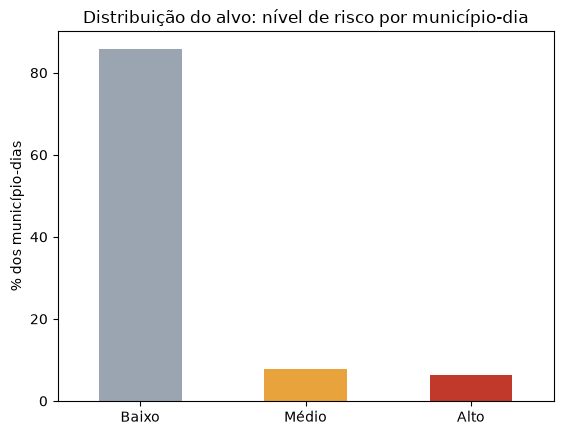

In [10]:
alvo = q("SELECT nivel_risco, count(*) AS dias FROM grade GROUP BY 1").set_index('nivel_risco').loc[['Baixo', 'Médio', 'Alto']]
alvo['%'] = (alvo['dias'] / alvo['dias'].sum() * 100).round(2)
print(alvo)
print()
print(q('SELECT count(DISTINCT id_municipio) AS municipios, count(DISTINCT dia) AS dias, count(*) AS linhas FROM grade'))

alvo['%'].plot(kind='bar', rot=0, color=[CORES_RISCO[n] for n in alvo.index])
plt.title('Distribuição do alvo: nível de risco por município-dia')
plt.ylabel('% dos município-dias')
plt.xlabel('')
plt.show()

**Baixo é o dia sem nenhum foco (85,81%).** Entre os dias com foco, o corte de 4 focos fica logo acima da
mediana (3 focos, seção 5.5) e separa o fogo isolado (Médio, 7,89%) do dia com vários pontos queimando ao mesmo tempo
(Alto, 6,30%), que é o que pede brigada de prontidão. As duas classes menores ficam acima de 5%.

**Limitação:** "nenhum foco detectado" não é exatamente "nenhum fogo". Nuvens e fogos pequenos escapam
do satélite. O alvo mede o fogo **visível por satélite**.

## 5. Exploração

### 5.1. Sazonalidade

     medio   alto
mes              
1     6.65   2.17
2     5.28   1.60
3     5.21   1.60
4     4.19   1.21
5     6.07   3.41
6     7.66   5.33
7     8.56   6.38
8    10.85  12.48
9    11.16  15.42
10   10.70  12.46
11    9.97   8.87
12    9.33   6.47


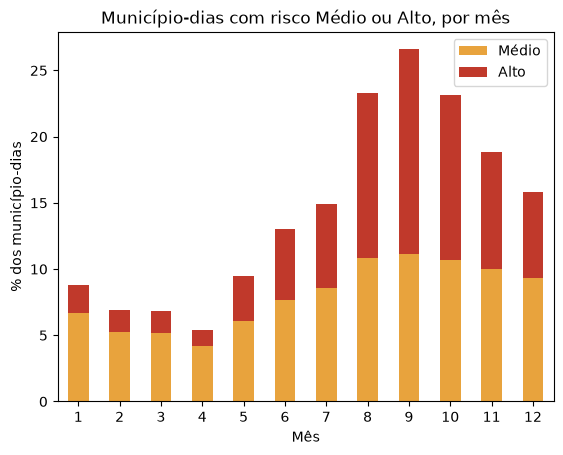

In [11]:
por_mes = q('''
    SELECT mes, avg((nivel_risco = 'Médio')::INT) * 100 AS medio, avg((nivel_risco = 'Alto')::INT) * 100 AS alto
    FROM grade GROUP BY 1 ORDER BY 1
''').set_index('mes').round(2)
print(por_mes)

por_mes.plot(kind='bar', stacked=True, rot=0, color=[LARANJA, VERMELHO])
plt.title('Município-dias com risco Médio ou Alto, por mês')
plt.ylabel('% dos município-dias')
plt.xlabel('Mês')
plt.legend(['Médio', 'Alto'])
plt.show()

**O fogo tem estação.** Em setembro, 15,42% dos município-dias são Alto; em abril, 1,21%. O mês entra como
feature, e a divisão de treino e teste da Etapa 2 vai precisar respeitar o calendário.

### 5.2. Persistência: o fogo de ontem

             pct_fogo_hoje  pct_alto_hoje     dias
focos_ontem                                       
0                     7.74           1.91  1810040
1 a 3                36.70          14.53   166579
4 a 10               60.56          35.77    67735
mais de 10           87.61          76.33    65160


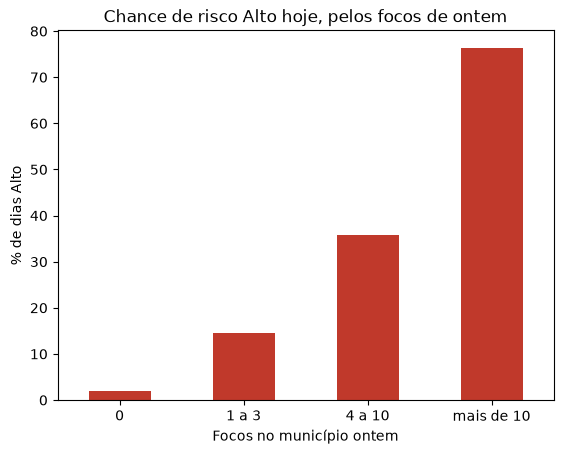

In [12]:
persistencia = q('''
    SELECT CASE WHEN focos_ontem = 0 THEN '0' WHEN focos_ontem <= 3 THEN '1 a 3'
                WHEN focos_ontem <= 10 THEN '4 a 10' ELSE 'mais de 10' END AS focos_ontem,
           avg((focos > 0)::INT) * 100 AS pct_fogo_hoje, avg((nivel_risco = 'Alto')::INT) * 100 AS pct_alto_hoje,
           count(*) AS dias
    FROM grade GROUP BY 1 ORDER BY min(focos_ontem)
''').set_index('focos_ontem').round(2)
print(persistencia)

persistencia['pct_alto_hoje'].plot(kind='bar', rot=0, color=VERMELHO)
plt.title('Chance de risco Alto hoje, pelos focos de ontem')
plt.ylabel('% de dias Alto')
plt.xlabel('Focos no município ontem')
plt.show()

**O fogo de ontem é o melhor aviso para hoje.** Sem foco ontem, só 1,91% dos dias são Alto; com mais
de 10 focos ontem, 76,33%. Isso vira o teste de hipótese 1 (seção 7) e o **modelo de referência**
da seção 8.

### 5.3. Estados e biomas

          pct_alto  municipios
sigla_uf                      
DF           44.33           1
RR           38.77          15
PA           26.05         143
AC           24.71          22
MT           22.41         141
AM           21.73          62
MA           20.03         217
TO           17.00         139


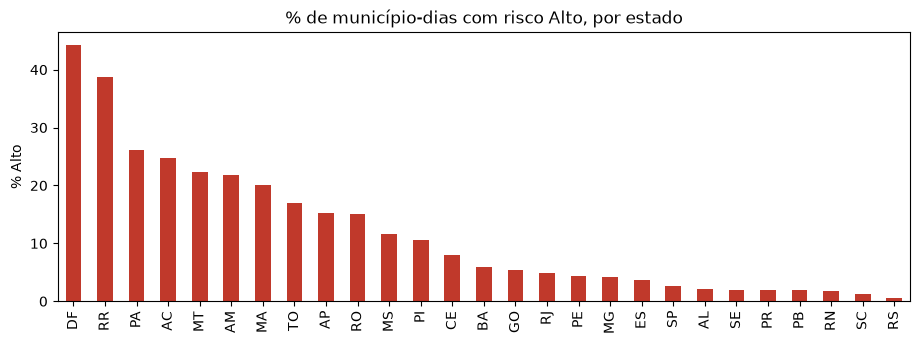

In [13]:
por_uf = q('''
    SELECT sigla_uf, avg((nivel_risco = 'Alto')::INT) * 100 AS pct_alto, count(DISTINCT id_municipio) AS municipios
    FROM grade GROUP BY 1 ORDER BY 2 DESC
''').set_index('sigla_uf').round(2)
print(por_uf.head(8))

por_uf['pct_alto'].plot(kind='bar', color=VERMELHO, figsize=(11, 3.5))
plt.title('% de município-dias com risco Alto, por estado')
plt.ylabel('% Alto')
plt.xlabel('')
plt.show()

In [14]:
por_bioma = q('''
    SELECT bioma, count(*) AS focos, round(100 * count(*) / sum(count(*)) OVER (), 2) AS pct_focos
    FROM queimadas WHERE satelite NOT IN ('GOES-16', 'MSG-03') GROUP BY 1 ORDER BY 2 DESC
''')
por_bioma

,bioma,focos,pct_focos
0,Amazônia,3555180,53.44
1,Cerrado,1892561,28.45
2,Pantanal,441487,6.64
3,Mata Atlântica,410817,6.18
4,Caatinga,343606,5.17
5,Pampa,8874,0.13
6,NaN,1,0.00


- **Estados:** Roraima (38,77%), Pará (26,05%) e Acre (24,71%) lideram em dias de risco Alto. O DF aparece
  no topo (44,33%), mas é um caso à parte: é um único município, e grande. O estado entra como feature.
- **Biomas:** Amazônia (53,44%) e Cerrado (28,45%) concentram a maior parte dos focos. O bioma fica só na análise, pelo motivo
  da seção 3.

### 5.4. Uso do solo

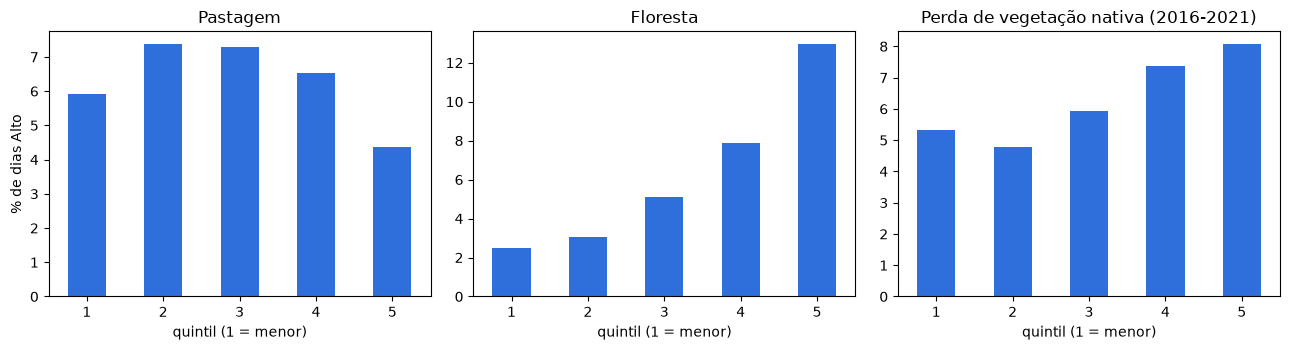

pct_pastagem     quintil menor: 5.91% Alto | quintil maior: 4.36% Alto
pct_floresta     quintil menor: 2.47% Alto | quintil maior: 12.96% Alto
perda_nativa_5a  quintil menor: 5.34% Alto | quintil maior: 8.08% Alto


In [15]:
municipios = q('''
    SELECT id_municipio, avg((nivel_risco = 'Alto')::INT) * 100 AS pct_alto,
           any_value(pct_pastagem) AS pct_pastagem, any_value(pct_floresta) AS pct_floresta,
           any_value(perda_nativa_5a) AS perda_nativa_5a
    FROM grade GROUP BY 1
''')
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6))
for eixo, coluna, titulo in zip(eixos, ['pct_pastagem', 'pct_floresta', 'perda_nativa_5a'],
                                ['Pastagem', 'Floresta', 'Perda de vegetação nativa (2016-2021)']):
    faixa = pd.qcut(municipios[coluna], 5, duplicates='drop')
    municipios.groupby(faixa, observed=True)['pct_alto'].mean().plot(kind='bar', ax=eixo, color=AZUL, rot=0)
    eixo.set_title(titulo)
    eixo.set_xlabel('quintil (1 = menor)')
    eixo.set_xticklabels(range(1, len(eixo.get_xticks()) + 1))
eixos[0].set_ylabel('% de dias Alto')
plt.tight_layout()
plt.show()

for coluna in ['pct_pastagem', 'pct_floresta', 'perda_nativa_5a']:
    faixa = pd.qcut(municipios[coluna], 5, labels=False, duplicates='drop')
    taxa = municipios.groupby(faixa)['pct_alto'].mean()
    print(f'{coluna:<16} quintil menor: {taxa.iloc[0]:.2f}% Alto | quintil maior: {taxa.iloc[-1]:.2f}% Alto')

- **Floresta é o que mais separa:** no quintil de municípios mais florestados, 12,96% dos dias são Alto, contra
  2,47% no menos florestado. São, em boa parte, os municípios da Amazônia, que também são os maiores
  (a área do município aparece na seção 6).
- **Perda de vegetação nativa:** quem mais perdeu vegetação nativa entre 2016 e 2021 tem 8,08% de dias Alto,
  contra 5,34% de quem menos perdeu. Faz sentido: queimada é uma das formas de abrir área.
- **Pastagem não tem relação clara com o risco:** a taxa sobe e desce entre os quintis (5,91% no menor,
  4,36% no maior).

O uso do solo carrega informação mesmo sendo de 2021.

### 5.5. Outliers e dados faltantes na base processada

In [16]:
print(q('SELECT quantile_cont(focos, [0.5, 0.9, 0.99, 0.999]) AS quantis, max(focos) AS maximo FROM grade WHERE focos > 0'))
print()
print(q('''SELECT count(*) FILTER (WHERE focos_ontem IS NULL) AS sem_historico,
           count(*) FILTER (WHERE pct_floresta IS NULL) AS sem_uso_do_solo FROM grade'''))

                        quantis  maximo
0  [3.0, 29.0, 356.0, 1847.004]   10620

   sem_historico  sem_uso_do_solo
0              0                0


- **Outliers:** há município-dias com até 10 620 focos, muito acima da mediana de 3 nos dias com fogo. São
  incêndios grandes reais. Como o alvo agrupa tudo a partir de 4 focos em "Alto", esses extremos não
  distorcem a classe; nas features de histórico, os modelos de árvore da Etapa 2 não são sensíveis a eles.
  **Ficam.**
- **Dados faltantes:** nenhum. O histórico só começa depois de 30 dias de série (os primeiros 30 dias
  saíram da grade), e todo município tem uso do solo.

## 6. Correlação

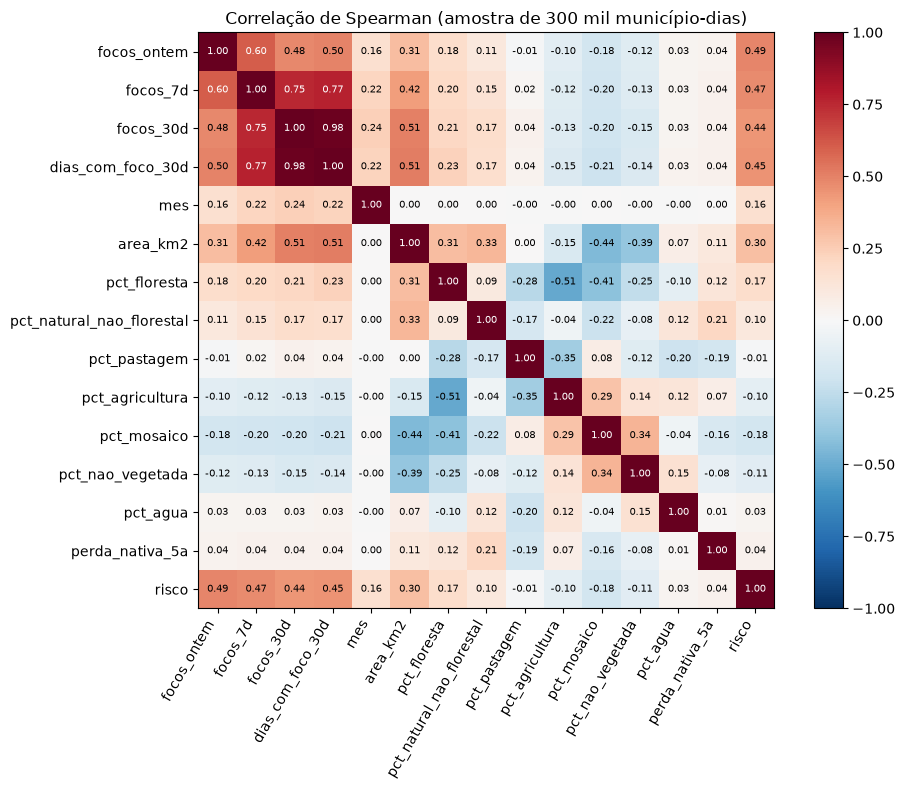

focos_ontem                  0.490
focos_7d                     0.470
dias_com_foco_30d            0.449
focos_30d                    0.442
area_km2                     0.304
pct_floresta                 0.173
mes                          0.161
pct_natural_nao_florestal    0.104
perda_nativa_5a              0.039
pct_agua                     0.026
pct_pastagem                -0.014
pct_agricultura             -0.100
pct_nao_vegetada            -0.115
pct_mosaico                 -0.180
Name: risco, dtype: float64


In [17]:
features = ['focos_ontem', 'focos_7d', 'focos_30d', 'dias_com_foco_30d', 'mes', 'area_km2',
            'pct_floresta', 'pct_natural_nao_florestal', 'pct_pastagem', 'pct_agricultura',
            'pct_mosaico', 'pct_nao_vegetada', 'pct_agua', 'perda_nativa_5a']
amostra = q(f'''
    SELECT {', '.join(features)}, CASE nivel_risco WHEN 'Baixo' THEN 0 WHEN 'Médio' THEN 1 ELSE 2 END AS risco
    FROM grade USING SAMPLE 300000 ROWS (reservoir, 12345)
''')
correlacao = amostra.corr(method='spearman')

fig, eixo = plt.subplots(figsize=(10, 8))
imagem = eixo.imshow(correlacao, cmap='RdBu_r', vmin=-1, vmax=1)
rotulos = list(correlacao.columns)
eixo.set_xticks(range(len(rotulos)))
eixo.set_xticklabels(rotulos, rotation=60, ha='right')
eixo.set_yticks(range(len(rotulos)))
eixo.set_yticklabels(rotulos)
for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        valor = correlacao.iloc[i, j]
        eixo.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=7,
                  color='white' if abs(valor) > 0.6 else 'black')
fig.colorbar(imagem)
plt.title('Correlação de Spearman (amostra de 300 mil município-dias)')
plt.tight_layout()
plt.show()

print(correlacao['risco'].drop('risco').sort_values(ascending=False).round(3))

A correlação é a de **Spearman**, que compara a ordem dos valores. Ela serve para o alvo ordenado
(Baixo < Médio < Alto) e não se deixa levar pelos outliers de focos. Foi calculada numa amostra aleatória
de 300 mil município-dias, suficiente para valores estáveis.

- **O histórico manda:** `focos_ontem` (0,490), `focos_7d` (0,470) e `dias_com_foco_30d` (0,449) são as mais
  ligadas ao risco. Elas também são muito correlacionadas entre si, porque medem o mesmo fogo em janelas
  diferentes. Os modelos de árvore lidam bem com isso; a regressão logística da Etapa 2 vai mostrar se
  vale manter todas.
- **Tamanho do município:** `area_km2` (0,304). Município maior tem mais área para pegar fogo.
- **O uso do solo ajuda, mas menos:** `pct_floresta` (0,173) e, no sentido contrário, `pct_mosaico` (-0,180).
- **Nenhuma passa de 0,7:** não há coluna "espelho" do alvo.

## 7. Testes de hipótese

### 7.1. O fogo de ontem aumenta a chance de fogo hoje?

**Premissa de negócio.** Se municípios com foco ontem têm mais chance de ter foco hoje, a regra mais
simples de prontidão ("mantenha a equipe onde houve fogo ontem") já funciona, e o modelo precisa no mínimo
reproduzi-la.

- **H0:** a chance de foco hoje é a mesma com ou sem foco ontem.
- **H1:** as chances são diferentes.
- **Teste:** qui-quadrado de independência, α = 0,05.

In [18]:
tabela = q('''
    SELECT (focos_ontem > 0) AS foco_ontem, (focos > 0) AS foco_hoje, count(*) AS dias FROM grade GROUP BY 1, 2
''').pivot(index='foco_ontem', columns='foco_hoje', values='dias')
tabela.index = ['sem foco ontem', 'com foco ontem']
tabela.columns = ['sem foco hoje', 'com foco hoje']
print(tabela)
print()

qui2, p_valor, graus, _ = stats.chi2_contingency(tabela)
taxas = tabela['com foco hoje'] / tabela.sum(axis=1)
print(f'Chance de foco hoje, com foco ontem: {taxas["com foco ontem"]:.2%}')
print(f'Chance de foco hoje, sem foco ontem: {taxas["sem foco ontem"]:.2%}')
p_texto = 'menor que 0,001' if p_valor < 0.001 else f'{p_valor:.4f}'
print(f'Qui-quadrado: {qui2:.1f} | graus de liberdade: {graus} | p-valor: {p_texto}')
print('Rejeitamos H0.' if p_valor < 0.05 else 'Não rejeitamos H0.')

                sem foco hoje  com foco hoje
sem foco ontem        1669948         140092
com foco ontem         140233         159241

Chance de foco hoje, com foco ontem: 53.17%
Chance de foco hoje, sem foco ontem: 7.74%
Qui-quadrado: 435620.6 | graus de liberdade: 1 | p-valor: menor que 0,001
Rejeitamos H0.


**Rejeitamos H0 (p-valor < 0,001).** Com foco ontem, a chance de foco hoje é **53,17%**; sem foco ontem,
**7,74%**: cerca de 7 vezes mais. A premissa se confirma, e o histórico de focos é a base do modelo.

Duas ressalvas sobre o teste:

- **Com 2 109 514 linhas, qualquer diferença daria p-valor minúsculo.** O que convence aqui é o **tamanho** da
  diferença, de cerca de 7 vezes, e não só o p-valor.
- **O qui-quadrado supõe observações independentes**, e o mesmo município aparece em dias seguidos. Isso
  deixa o p-valor otimista. Mas uma diferença desse tamanho não desaparece com essa correção, e é
  justamente a dependência entre dias que o modelo vai aproveitar.

### 7.2. O ar é mais seco nos dias com fogo? (usando o BDMEP)

**Premissa.** Se a umidade do ar é menor nos dias com foco, o clima tem informação sobre o risco, e vale
buscar dados de clima para o período inteiro numa versão futura do modelo. Este teste usa o único período
em que queimadas e BDMEP coexistem (1º de janeiro a 12 de fevereiro de 2025) e os municípios com estação.

- **H0:** a umidade relativa mínima média é a mesma nos dias com e sem foco.
- **H1:** as médias são diferentes.
- **Teste:** t de Welch (duas médias, sem supor variâncias iguais), α = 0,05.

In [19]:
clima = q('''
    WITH diario AS (
        SELECT e.id_municipio, b.data AS dia, min(b.umidade_rel_min) AS umidade_min
        FROM (SELECT DISTINCT * FROM bdmep) b JOIN estacoes e USING (id_estacao)
        WHERE b.umidade_rel_min IS NOT NULL
        GROUP BY 1, 2)
    SELECT d.umidade_min, g.focos > 0 AS teve_foco
    FROM diario d JOIN grade g USING (id_municipio, dia)
''')
com_foco = clima.loc[clima['teve_foco'], 'umidade_min']
sem_foco = clima.loc[~clima['teve_foco'], 'umidade_min']
print(f'Município-dias com estação no período comum: {len(clima)} ({len(com_foco)} com foco)')
print(f'Umidade mínima média com foco: {com_foco.mean():.2f}% | sem foco: {sem_foco.mean():.2f}%')

t, p_valor = stats.ttest_ind(com_foco, sem_foco, equal_var=False)
p_texto = 'menor que 0,001' if p_valor < 0.001 else f'{p_valor:.4f}'
print(f't de Welch: {t:.2f} | p-valor: {p_texto}')
print('Rejeitamos H0.' if p_valor < 0.05 else 'Não rejeitamos H0.')

Município-dias com estação no período comum: 17764 (2712 com foco)
Umidade mínima média com foco: 43.05% | sem foco: 52.00%
t de Welch: -34.75 | p-valor: menor que 0,001
Rejeitamos H0.


**Rejeitamos H0 (p-valor < 0,001).** Nos dias com foco, a umidade mínima média foi de **43,05%**, contra
**52,00%** nos dias sem foco, uma diferença de cerca de 9 pontos. O clima tem informação sobre o risco,
mesmo na época de chuva.

**Ressalva:** a comparação mistura municípios de regiões diferentes. Parte da diferença pode vir do lugar
(municípios com mais fogo ficam em regiões mais secas), e não só do dia. O teste mostra que umidade e
fogo andam juntos, não que um causa o outro; para o modelo, isso basta, porque ele precisa de sinais que
antecipem o risco. Como o BDMEP fornecido não cobre 2024, completar a série de clima fica como a principal
melhoria para uma próxima versão.

## 8. Modelo de referência e KPIs

A regra mais simples de prontidão é **"o risco de hoje é o de ontem"**. Ela não usa nada além do próprio
alvo do dia anterior, e é a régua que o modelo da Etapa 2 precisa superar:

In [20]:
from sklearn.metrics import classification_report, f1_score

referencia = q('''
    SELECT nivel_risco AS real,
           CASE WHEN focos_ontem >= 4 THEN 'Alto' WHEN focos_ontem >= 1 THEN 'Médio' ELSE 'Baixo' END AS previsto
    FROM grade
''')
print(classification_report(referencia['real'], referencia['previsto'], labels=['Baixo', 'Médio', 'Alto'], digits=4))
print(f"F1 macro da regra 'hoje = ontem': {f1_score(referencia['real'], referencia['previsto'], average='macro'):.4f}")

              precision    recall  f1-score   support

       Baixo     0.9226    0.9225    0.9226   1810181
       Médio     0.2217    0.2218    0.2217    166502
        Alto     0.5566    0.5569    0.5567    132831

    accuracy                         0.8442   2109514
   macro avg     0.5670    0.5671    0.5670   2109514
weighted avg     0.8442    0.8442    0.8442   2109514



F1 macro da regra 'hoje = ontem': 0.5670


**KPIs do projeto**

| Tipo | Meta | Referência ("hoje = ontem") |
|---|---|---|
| Técnico | No conjunto de teste, F1 macro acima da regra de referência | F1 macro 0,5670 |
| Técnico | Recall da classe Alto acima da regra de referência | recall Alto 0,5569 |
| Negócio | Custo total de prontidão menor que o da regra de referência. O custo soma as equipes posicionadas em dias que não pegam fogo (alarmes falsos) e os dias Alto sem equipe (incêndios sem aviso), e vira reais na Etapa 2 | precisão Alto 0,5566 e recall Alto 0,5569 |

O **F1 macro** dá o mesmo peso às três classes, o que impede o modelo de "ganhar" só acertando os dias
Baixo, que são 85,81% da base. O **recall do Alto** mede quantos dias críticos o modelo avisa a tempo.
Na Etapa 2, a precisão e o recall do Alto viram reais: custo de uma equipe de prontidão contra o custo de
um incêndio que começa sem equipe por perto.

*Observação: a regra de referência aqui é avaliada na grade inteira, só para calibrar as metas. Na Etapa 2,
ela e os modelos serão comparados no mesmo conjunto de teste.*

## 9. Base processada

In [21]:
destino = cb.salvar(con)
print(f'Salva em: {destino.relative_to(cb.RAIZ)}')
base = pd.read_parquet(destino)
base.info()

Salva em: dados\processado\grade_municipio_dia.parquet
<class 'pandas.DataFrame'>
RangeIndex: 2109514 entries, 0 to 2109513
Data columns (total 20 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   id_municipio               int64  
 1   sigla_uf                   str    
 2   dia                        object 
 3   focos                      int64  
 4   focos_ontem                int64  
 5   focos_7d                   float64
 6   focos_30d                  float64
 7   dias_com_foco_30d          float64
 8   mes                        int64  
 9   dia_do_ano                 int64  
 10  area_km2                   float64
 11  pct_floresta               float64
 12  pct_natural_nao_florestal  float64
 13  pct_pastagem               float64
 14  pct_agricultura            float64
 15  pct_mosaico                float64
 16  pct_nao_vegetada           float64
 17  pct_agua                   float64
 18  perda_nativa_5a            float64
 19

O dicionário da base processada, com a origem e o significado de cada coluna, está em
`dicionario_dados.txt`.

## 10. Conclusões

**Sobre os dados**
1. **A base de queimadas tem viés de sobrevivência:** só registra onde houve fogo (67,01% dos focos estão em
   risco crítico do INPE). A base do modelo é uma grade de 2 109 514 município-dias que inclui os dias sem
   fogo.
2. **As bases quase não se encontram no tempo:** queimadas e clima coexistem por só 43 dias, e o uso do
   solo é de 2021. O clima ficou fora das features e entrou num teste de hipótese.
3. **O dicionário do MapBiomas fornecido não bate com os dados.** Os códigos seguem a legenda oficial da
   Coleção 8, agrupados em 7 grupos.
4. `risco_fogo`, `dias_sem_chuva`, `precipitacao` e bioma ficaram fora das features, porque só existem
   (ou só são conhecidos) quando já há fogo.

**Sobre o risco**
1. **O fogo de ontem é o melhor aviso:** com foco ontem, a chance de foco hoje é 53,17%, contra 7,74%
   (qui-quadrado, p < 0,001).
2. **O ar seco acompanha o fogo:** umidade mínima de 43,05% nos dias com foco, contra 52,00% (Welch,
   p < 0,001).
3. **Há estação do fogo** (agosto a outubro) e **geografia do fogo** (uso do solo e perda de vegetação nativa).

**Para a Etapa 2**
- O alvo tem três classes desequilibradas (Baixo 85,81%); as métricas principais serão o F1 macro e o recall do
  Alto, com ajuste de pesos de classe.
- A divisão de treino e teste vai ser **por tempo** (treinar no passado, testar no futuro), porque as
  features usam o histórico e o fogo tem estação.
- A régua é a regra "hoje = ontem": F1 macro 0,5670.